# 1. Objetivo del experimento

El objetivo de este experimento es desarrollar y evaluar modelos de aprendizaje automático capaces de clasificar pacientes según su condición vertebral utilizando variables biomecánicas obtenidas de estudios clínicos.

Se comparará un modelo de referencia con un Árbol de Decisión para analizar su capacidad predictiva y comprender qué variables aportan mayor información durante el proceso de clasificación.

# 2. Fuente y descripción del dataset

El conjunto de datos utilizado corresponde al Vertebral Column Dataset disponible en el repositorio UCI Machine Learning Repository.

El dataset contiene mediciones biomecánicas relacionadas con la columna vertebral de diversos pacientes.

Las variables representan características anatómicas de la pelvis y la columna, utilizadas para clasificar diferentes condiciones clínicas.

## Variables

- pelvic_incidence
- pelvic_tilt
- lumbar_lordosis_angle
- sacral_slope
- pelvic_radius
- degree_spondylolisthesis

## Variable objetivo

- class

# 3. Carga y validación de los datos

En esta sección se realiza la importación del dataset y una validación inicial para verificar dimensiones, tipos de datos y posibles valores faltantes.

In [1]:
import pandas as pd
import numpy as np

from ucimlrepo import fetch_ucirepo

In [2]:
vertebral_column = fetch_ucirepo(id=212)

X = vertebral_column.data.features
y = vertebral_column.data.targets

df = pd.concat([X, y], axis=1)

df.head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,Hernia
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,Hernia
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,Hernia
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,Hernia
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,Hernia


In [3]:
df.shape

(310, 7)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt               310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    str    
dtypes: float64(6), str(1)
memory usage: 17.1 KB


In [5]:
df.isnull().sum()

pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
class                       0
dtype: int64

# 4. Análisis exploratorio
Se exploran las distribuciones de las variables, la composición de las clases y las relaciones entre atributos.

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

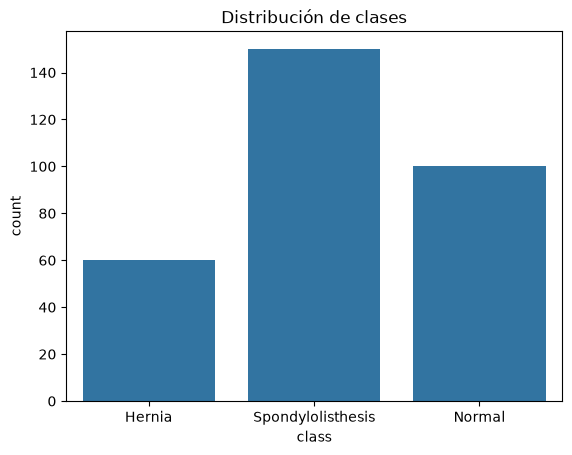

In [7]:
sns.countplot(data=df, x='class')

plt.title("Distribución de clases")
plt.show()

In [8]:
df.describe()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
count,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,60.496653,17.542822,51.930930,42.953831,117.920655,26.296694
std,17.236520,10.008330,18.554064,13.423102,13.317377,37.559027
min,26.147921,-6.554948,14.000000,13.366931,70.082575,-11.058179
25%,46.430294,10.667069,37.000000,33.347122,110.709196,1.603727
50%,58.691038,16.357689,49.562398,42.404912,118.268178,11.767934
75%,72.877696,22.120395,63.000000,52.695888,125.467674,41.287352
max,129.834041,49.431864,125.742385,121.429566,163.071041,418.543082


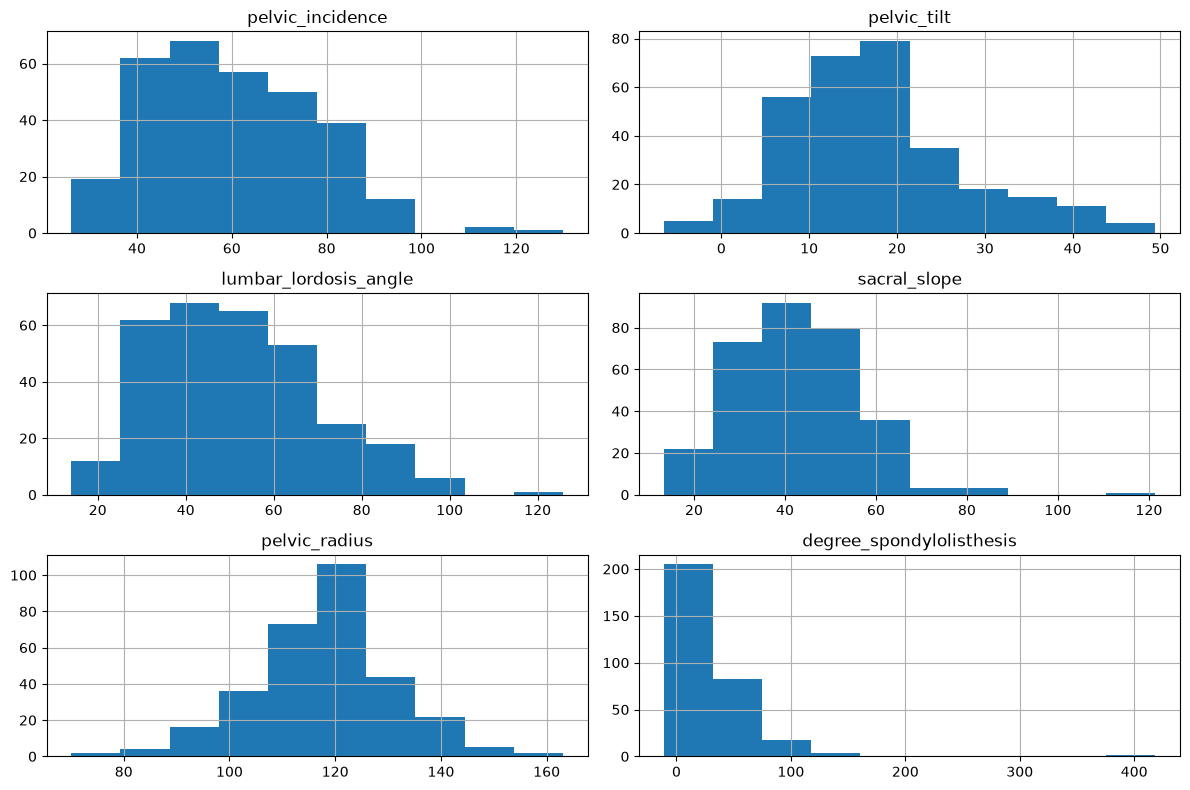

In [9]:
df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()


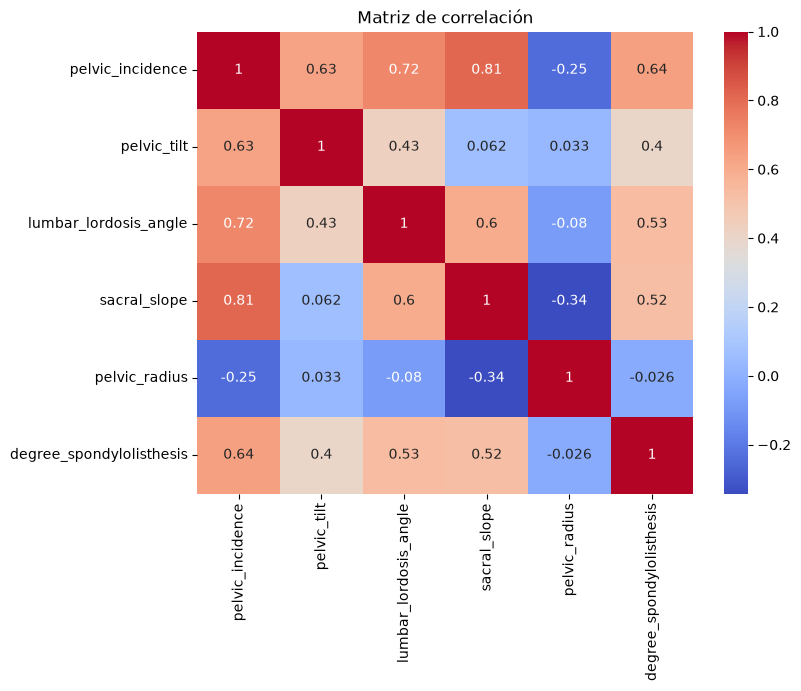

In [10]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Matriz de correlación")
plt.show()